# USD–INR Market-Surveillance Tool — Stage 0: Getting the Data

**What this whole project is.** We are building a tool that *watches the exchange rate between the US dollar (USD) and the Indian rupee (INR)* and tries to automatically spot days when that rate behaved **abnormally** — unusually turbulent or jumpy. Later we will check whether those flagged days line up with real economic events (a financial crisis, a policy shock, and so on). The point is to demonstrate, that a machine-learning approach can highlight genuine episodes of market stress.



## Stage 0

Here we will load the libraries, download the data, verify it the data loaded cleanly, run few sanity chekcs and save the data.

### Step 1 — Load the libraries we need and check versions

In [75]:
import pandas as pd
import yfinance as yf

print("pandas version :", pd.__version__)
print("yfinance version:", yf.__version__)

pandas version : 2.2.2
yfinance version: 0.2.66


### Step 2 — Get the daily USD–INR history (Also check if it is already downloaded)


In [76]:
import os

# --- Reproducibility switch -------------------------------------------------
# False (default): load the frozen data/usd_inr_raw.csv -> results reproduce exactly.
# True           : deliberately re-download a fresh copy from yfinance and re-freeze it.
# (A fresh download also happens automatically if the frozen file does not exist yet.)
REFRESH_DATA = False
RAW_PATH = "usd_inr_raw.csv"
# ---------------------------------------------------------------------------

if REFRESH_DATA or not os.path.exists(RAW_PATH):
    # Download the longest available daily history of USD-INR.
    raw = yf.download("USDINR=X", period="max", interval="1d", auto_adjust=False, progress=False)
    data_was_downloaded = True
    print("Source: FRESH DOWNLOAD from yfinance (ticker USDINR=X).")
else:
    # Reproducible default: load the exact frozen dataset we saved earlier.
    raw = pd.read_csv(RAW_PATH, index_col=0, parse_dates=[0])
    data_was_downloaded = False
    print("Source: loaded the FROZEN file", RAW_PATH, "(reproducible mode; no download).")

print("REFRESH_DATA =", REFRESH_DATA, "| data_was_downloaded =", data_was_downloaded)
print("Table size (rows, columns):", raw.shape)
print(raw.head()) #look at top 5 rows
print(raw.tail()) #look at bottom 5 rows

Source: loaded the FROZEN file usd_inr_raw.csv (reproducible mode; no download).
REFRESH_DATA = False | data_was_downloaded = False
Table size (rows, columns): (5859, 6)
            Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2003-12-01  45.709999  45.709999  45.728001  45.615002  45.709000       0
2003-12-02  45.629002  45.629002  45.719002  45.560001  45.709000       0
2003-12-03  45.549999  45.549999  45.655998  45.474998  45.632000       0
2003-12-04  45.548000  45.548000  45.612999  45.519001  45.548000       0
2003-12-05  45.449001  45.449001  45.566002  45.449001  45.549999       0
            Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2026-06-30  94.790497  94.790497  94.897903  94.465302  94.790497       0
2026-07-01  94.917999  94.917999  95.263901  94.531197  94.917999       0
2026-07-02  95.4

### Step 3 — Tidy up the column labels

**What this does.** It simplifies the column labels of the table. Check whether the columns are a MultiIndex; if they are, we keep only the top label of each column.

In [77]:
# If yfinance returned two-level (MultiIndex) columns, keep only the top level.
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = [top_label for (top_label, _ticker) in raw.columns]

print("Final column labels:", list(raw.columns))

Final column labels: ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


### Step 4 — Verify the data loaded cleanly

Here we read the first 5 rows, last 5 rows, check the number of rows, date range, names of columns, missing value in columns.

In [78]:
print("=" * 60)
print("DATA-QUALITY SUMMARY  (USD-INR daily, source: yfinance)")
print("=" * 60)

print("\n--- First 5 rows ---")
print(raw.head())

print("\n--- Last 5 rows ---")
print(raw.tail())

print("\n--- Number of rows (trading days) ---")
print(len(raw))

print("\n--- Date range ---")
print("Earliest date:", raw.index.min().date())
print("Latest date  :", raw.index.max().date())

print("\n--- Column names and data types (dtypes) ---")
print(raw.dtypes)

print("\n--- Missing values per column ---")
print(raw.isna().sum())

DATA-QUALITY SUMMARY  (USD-INR daily, source: yfinance)

--- First 5 rows ---
            Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2003-12-01  45.709999  45.709999  45.728001  45.615002  45.709000       0
2003-12-02  45.629002  45.629002  45.719002  45.560001  45.709000       0
2003-12-03  45.549999  45.549999  45.655998  45.474998  45.632000       0
2003-12-04  45.548000  45.548000  45.612999  45.519001  45.548000       0
2003-12-05  45.449001  45.449001  45.566002  45.449001  45.549999       0

--- Last 5 rows ---
            Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2026-06-30  94.790497  94.790497  94.897903  94.465302  94.790497       0
2026-07-01  94.917999  94.917999  95.263901  94.531197  94.917999       0
2026-07-02  95.417503  95.417503  95.473396  94.884804  95.417503       0
2026-07-03  9

### Step 5 — A few sanity checks for broken data

Check for "missing values" alone would not catch. We also check duplicate dates, non-positive pices, largest one-day move to see any abnormal gap, largest gap between two consecutive dates and check OHLC consistency i.e. the opening and closing prices are within the [low, high] range or not. If it is outside the low-high range, we call it a bad tick.


In [79]:
close = raw["Close"]

print("Duplicate dates                 :", int(raw.index.duplicated().sum()))
print("Non-positive Close prices       :", int((close <= 0).sum()))
print("Lowest  Close in history        :", round(float(close.min()), 4))
print("Highest Close in history        :", round(float(close.max()), 4))

daily_pct_change = close.pct_change().abs()
#print(daily_pct_change.head())
#print(daily_pct_change.tail())
print("Largest one-day move (percent)  :", round(float(daily_pct_change.max()) * 100, 2), "%")
print("Days with a >5% one-day move    :", int((daily_pct_change > 0.05).sum()))

gap_in_days = raw.index.to_series().diff().dt.days
print("Largest gap between rows (days) :", int(gap_in_days.max()))

# --- OHLC internal consistency: Close must lie within [Low, High] ---
outside_range = (raw["Close"] - raw["High"]).clip(lower=0) + (raw["Low"] - raw["Close"]).clip(lower=0)
outside_pct = outside_range / raw["Close"] * 100
print("\nRows with Close outside [Low, High] :", int((outside_pct > 0).sum()),
      "(most are tiny feed-rounding noise)")
print("...of which MATERIAL (>0.5% outside)  :", int((outside_pct > 0.5).sum()))
material = outside_pct[outside_pct > 0.5].sort_values(ascending=False)
if len(material):
    print("Material bad ticks (Close vs the day's High/Low):")
    print(raw.loc[material.index, ["High", "Low", "Close"]].assign(pct_outside=material.round(3)))

Duplicate dates                 : 0
Non-positive Close prices       : 0
Lowest  Close in history        : 39.045
Highest Close in history        : 96.5658
Largest one-day move (percent)  : 6.29 %
Days with a >5% one-day move    : 3
Largest gap between rows (days) : 26

Rows with Close outside [Low, High] : 240 (most are tiny feed-rounding noise)
...of which MATERIAL (>0.5% outside)  : 10
Material bad ticks (Close vs the day's High/Low):
                 High        Low      Close  pct_outside
Date                                                    
2012-01-31  49.735001  49.318001  52.493000        5.254
2012-01-27  49.810001  49.294998  52.493000        5.111
2023-11-02  83.325897  83.170502  85.194000        2.193
2011-10-28  48.919998  48.627998  49.790001        1.747
2012-04-04  51.233002  50.720001  50.250000        0.935
2009-03-27  50.518002  50.098999  50.924999        0.799
2009-02-06  48.750000  48.462002  48.090000        0.774
2009-02-20  49.952999  49.410999  49.068001   

### Step 6 — Freeze the raw data to disk (only when freshly downloaded)

This is done to ensure consistency in analysis and reproducibility of charts.

In [80]:
if data_was_downloaded:
    raw.to_csv(RAW_PATH)
    print("Freshly downloaded data FROZEN to:", RAW_PATH)
else:
    print("Reproducible mode: using the existing frozen file (not re-saved):", RAW_PATH)

Reproducible mode: using the existing frozen file (not re-saved): usd_inr_raw.csv


### Step 7 — Reload the saved file and verify it reads back clean

In [81]:
reloaded = pd.read_csv(RAW_PATH, index_col=0, parse_dates=[0])

print("=" * 60)
print("RE-VERIFICATION OF THE SAVED FILE (read back from disk)")
print("=" * 60)

print("\n--- First 5 rows ---")
print(reloaded.head())

print("\n--- Last 5 rows ---")
print(reloaded.tail())

print("\n--- Number of rows ---")
print(len(reloaded))

print("\n--- Date range ---")
print("Earliest date:", reloaded.index.min().date())
print("Latest date  :", reloaded.index.max().date())

print("\n--- Column names and data types (dtypes) ---")
print(reloaded.dtypes)

print("\n--- Missing values per column ---")
print(reloaded.isna().sum())

# Faithful-reload check: verify what matters, and print the tiny leftover difference.
print("\n--- Faithful-reload check ---")
import numpy as np

shape_ok   = (raw.shape == reloaded.shape)
dates_ok   = bool((raw.index.normalize() == reloaded.index.normalize()).all())
dtypes_ok  = bool((raw.dtypes.values == reloaded.dtypes.values).all())
new_missing = int(reloaded.isna().sum().sum())
max_value_diff = float(np.abs(raw.to_numpy() - reloaded.to_numpy()).max())
TOLERANCE = 1e-9

print("Shape unchanged                 :", shape_ok)
print("Dates exactly identical         :", dates_ok)
print("Column data types match         :", dtypes_ok)
print("Missing values introduced       :", new_missing)
print("Largest value difference        :", max_value_diff, f"(tolerance {TOLERANCE})")

passed = shape_ok and dates_ok and dtypes_ok and (new_missing == 0) and (max_value_diff < TOLERANCE)
print("\nRESULT:", "PASS - saved file reads back clean and faithful to full precision."
      if passed else "FAIL - investigate before proceeding to Stage 1.")

RE-VERIFICATION OF THE SAVED FILE (read back from disk)

--- First 5 rows ---
            Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2003-12-01  45.709999  45.709999  45.728001  45.615002  45.709000       0
2003-12-02  45.629002  45.629002  45.719002  45.560001  45.709000       0
2003-12-03  45.549999  45.549999  45.655998  45.474998  45.632000       0
2003-12-04  45.548000  45.548000  45.612999  45.519001  45.548000       0
2003-12-05  45.449001  45.449001  45.566002  45.449001  45.549999       0

--- Last 5 rows ---
            Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2026-06-30  94.790497  94.790497  94.897903  94.465302  94.790497       0
2026-07-01  94.917999  94.917999  95.263901  94.531197  94.917999       0
2026-07-02  95.417503  95.417503  95.473396  94.884804  95.417503       0
2026-07-03  9

## Stage 0 — outcome

If every cell above ran without errors, we now have a verified data which is saved locally. We can now start stage 1.

<!-- STAGE1_START -->
# Stage 1 — Measuring Daily Returns and Rolling Volatility




1. **Daily returns** — how much the rate moved from one day to the next
2. **Rolling volatility** — how much those daily moves have been bouncing around *recently*.

### Step 1.1 — Reload the verified file and confirm we are on the same clean data



In [82]:
import pandas as pd
import numpy as np

prices = pd.read_csv("usd_inr_raw.csv", index_col=0, parse_dates=[0])

print("First 5 rows:\n", prices.head(), "\n")
print("Last 5 rows:\n", prices.tail(), "\n")
print("Number of rows :", len(prices))
print("Date range     :", prices.index.min().date(), "->", prices.index.max().date())
print("\nColumn dtypes:\n", prices.dtypes)
print("\nMissing values per column:\n", prices.isna().sum())

First 5 rows:
             Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2003-12-01  45.709999  45.709999  45.728001  45.615002  45.709000       0
2003-12-02  45.629002  45.629002  45.719002  45.560001  45.709000       0
2003-12-03  45.549999  45.549999  45.655998  45.474998  45.632000       0
2003-12-04  45.548000  45.548000  45.612999  45.519001  45.548000       0
2003-12-05  45.449001  45.449001  45.566002  45.449001  45.549999       0 

Last 5 rows:
             Adj Close      Close       High        Low       Open  Volume
Date                                                                     
2026-06-30  94.790497  94.790497  94.897903  94.465302  94.790497       0
2026-07-01  94.917999  94.917999  95.263901  94.531197  94.917999       0
2026-07-02  95.417503  95.417503  95.473396  94.884804  95.417503       0
2026-07-03  95.527100  95.527100  95.609703  95.057602  95.527100       0
2026-07

### Step 1.2 — Find the gaps in the calendar

We compute day-to-day difference and choose a threshold of 3 days (Friday to Monday). If there is a public holiday, the gap could reach 4 days. So, anything bigger than 4 calender days, we call it an abnormal gap.
We then print how many abnormal gaps there are and exactly where each one falls and how large it is.

In [83]:
# Calendar-day gap between each row and the previous row.
gap_calendar_days = prices.index.to_series().diff().dt.days
#print(gap_calendar_days.head())
GAP_THRESHOLD_DAYS = 4   # more than a long weekend (3-4 days) => abnormal / missing data
abnormal_gaps = gap_calendar_days[gap_calendar_days > GAP_THRESHOLD_DAYS]
#print(abnormal_gaps)
print("Threshold for an 'abnormal' gap: more than", GAP_THRESHOLD_DAYS, "calendar days")
print("Number of abnormal gaps found  :", len(abnormal_gaps))
print("\nEach abnormal gap (previous trading day -> next trading day = gap in calendar days):")
for date_after, gap in abnormal_gaps.items():
    pos = prices.index.get_loc(date_after)
    date_before = prices.index[pos - 1]
    print(f"  {date_before.date()}  ->  {date_after.date()}   =  {int(gap)} calendar days")

Threshold for an 'abnormal' gap: more than 4 calendar days
Number of abnormal gaps found  : 2

Each abnormal gap (previous trading day -> next trading day = gap in calendar days):
  2008-07-31  ->  2008-08-26   =  26 calendar days
  2025-04-17  ->  2025-04-22   =  5 calendar days


### Step 1.3 — Calculate daily returns and neutralise the gap-spanning ones

We use log return in daily return.

In [84]:
# Log return: natural log of (today's close / yesterday's close).
prices["log_return"] = np.log(prices["Close"] / prices["Close"].shift(1))

# Mark every row whose return spans an abnormal gap.
prices["gap_spanned"] = gap_calendar_days > GAP_THRESHOLD_DAYS

# Count NaNs before, blank out the gap-spanning returns, count after.
nan_before = int(prices["log_return"].isna().sum())   # only the very first row (no prior day)
prices.loc[prices["gap_spanned"], "log_return"] = np.nan #make log_return as NaN where gap is more than 3 days
nan_after = int(prices["log_return"].isna().sum())

print("Returns that are NaN before gap-masking:", nan_before, "(just the first row, which has no previous day)")
print("Returns that are NaN after  gap-masking:", nan_after)
print("=> Returns set to NaN specifically because they span a gap:", nan_after - nan_before)
print("   That is", round(100 * (nan_after - nan_before) / len(prices), 4), "% of all rows -- confirming the gap issue is tiny.")

Returns that are NaN before gap-masking: 1 (just the first row, which has no previous day)
Returns that are NaN after  gap-masking: 3
=> Returns set to NaN specifically because they span a gap: 2
   That is 0.0341 % of all rows -- confirming the gap issue is tiny.


### Step 1.4 — Find and neutralise "bad ticks" (impossible Close prices)

We follow the following two steps here:
1. **Flag** the rows where the Close is *materially* outside the High–Low range. "Material" means more than **0.5%** outside — small violations are just feed rounding and we leave those alone.
2. Set to `NaN` the log returns **into** each bad day (yesterday → bad day) **and out of** it (bad day → next day), because both of those day-to-day moves are computed using the corrupted Close and are therefore untrustworthy.
We then report how many rows were flagged and how many return values were blanked.

In [85]:
# A Close is impossible if it lies outside the day's own [Low, High] range.
close_outside_range = (prices["Close"] - prices["High"]).clip(lower=0) \
                    + (prices["Low"] - prices["Close"]).clip(lower=0)
outside_pct = close_outside_range / prices["Close"] * 100

BAD_TICK_THRESHOLD_PCT = 0.5   # ignore tiny feed-rounding; flag only material violations
prices["bad_tick"] = outside_pct > BAD_TICK_THRESHOLD_PCT

print("Material bad-tick rows (Close >%.1f%% outside [Low, High]): %d"
      % (BAD_TICK_THRESHOLD_PCT, int(prices["bad_tick"].sum())))
print(prices.loc[prices["bad_tick"], ["High", "Low", "Close"]]
      .assign(pct_outside=outside_pct[prices["bad_tick"]].round(3)))

# Blank the returns INTO a bad day and OUT of a bad day (the next row uses the bad Close).
nan_before_badtick = int(prices["log_return"].isna().sum())
into_bad = prices["bad_tick"]
out_of_bad = prices["bad_tick"].shift(1, fill_value=False)
prices.loc[into_bad | out_of_bad, "log_return"] = np.nan
nan_after_badtick = int(prices["log_return"].isna().sum())

print("\nReturn values blanked because of bad ticks:", nan_after_badtick - nan_before_badtick,
      "(the return into and out of each of the", int(prices["bad_tick"].sum()), "bad days)")
print("Total NaN returns now (first row + gaps + bad ticks):", nan_after_badtick,
      "=", round(100 * nan_after_badtick / len(prices), 4), "% of all rows")

Material bad-tick rows (Close >0.5% outside [Low, High]): 10
                 High        Low      Close  pct_outside
Date                                                    
2009-02-06  48.750000  48.462002  48.090000        0.774
2009-02-20  49.952999  49.410999  49.068001        0.699
2009-03-27  50.518002  50.098999  50.924999        0.799
2010-11-08  44.452999  44.205002  43.900002        0.695
2011-10-28  48.919998  48.627998  49.790001        1.747
2012-01-27  49.810001  49.294998  52.493000        5.111
2012-01-31  49.735001  49.318001  52.493000        5.254
2012-04-04  51.233002  50.720001  50.250000        0.935
2018-10-19  73.680000  73.269997  74.160004        0.647
2023-11-02  83.325897  83.170502  85.194000        2.193

Return values blanked because of bad ticks: 20 (the return into and out of each of the 10 bad days)
Total NaN returns now (first row + gaps + bad ticks): 23 = 0.3926 % of all rows


### Step 1.5 — Measure rolling volatility



**What this does.** For each day, it looks back over the most recent **21 trading days** (about one trading month — there are roughly 21 business days in a month) and computes the standard deviation of the log returns in that window. The result is a day-by-day series of "how turbulent has the last month been."


In [86]:
ROLLING_WINDOW = 21   # trading days (~1 month); tunable -- see explanation above

prices["roll_vol_21"] = prices["log_return"].rolling(window=ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std()

valid = prices["roll_vol_21"].notna()
print("Rolling window length        :", ROLLING_WINDOW, "trading days")
print("First date with a volatility :", prices["roll_vol_21"].first_valid_index().date())
print("Number of volatility values  :", int(valid.sum()), "of", len(prices), "rows")
print("\nRolling volatility summary (standard deviation of daily log returns):")
print(prices["roll_vol_21"].describe())

Rolling window length        : 21 trading days
First date with a volatility : 2003-12-30
Number of volatility values  : 5608 of 5859 rows

Rolling volatility summary (standard deviation of daily log returns):
count    5608.000000
mean        0.003842
std         0.002070
min         0.000434
25%         0.002532
50%         0.003385
75%         0.004694
max         0.017211
Name: roll_vol_21, dtype: float64


### Step 1.6 — Assemble the feature table

We gathers the pieces we built into one tidy table: the date (as the row label), the closing price, the daily log return, the two data-quality flags (`gap_spanned` and `bad_tick`), and the rolling volatility.

In [87]:
features = prices[["Close", "log_return", "gap_spanned", "bad_tick", "roll_vol_21"]].copy()
features = features.rename(columns={"Close": "close"})

print("Feature table shape (rows, columns):", features.shape)
print("\nFirst 5 rows:\n", features.head())
print("\nLast 5 rows:\n", features.tail())

Feature table shape (rows, columns): (5859, 5)

First 5 rows:
                 close  log_return  gap_spanned  bad_tick  roll_vol_21
Date                                                                 
2003-12-01  45.709999         NaN        False     False          NaN
2003-12-02  45.629002   -0.001774        False     False          NaN
2003-12-03  45.549999   -0.001733        False     False          NaN
2003-12-04  45.548000   -0.000044        False     False          NaN
2003-12-05  45.449001   -0.002176        False     False          NaN

Last 5 rows:
                 close  log_return  gap_spanned  bad_tick  roll_vol_21
Date                                                                 
2026-06-30  94.790497    0.004549        False     False     0.005115
2026-07-01  94.917999    0.001344        False     False     0.004950
2026-07-02  95.417503    0.005249        False     False     0.005052
2026-07-03  95.527100    0.001148        False     False     0.004589
2026-07-05  

### Step 1.7 — Chart 1: the exchange rate over time



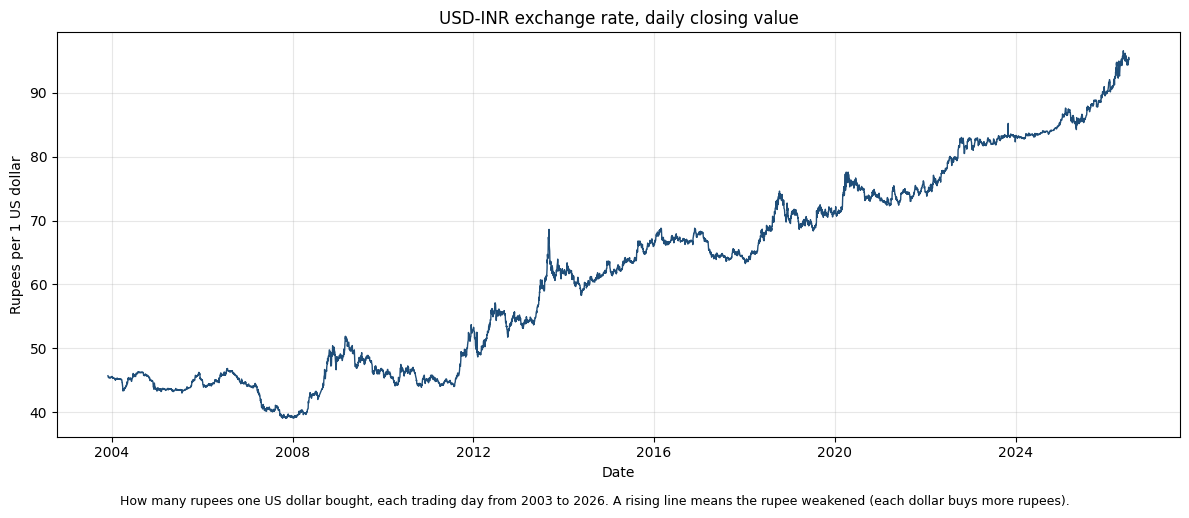

In [88]:
import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(features.index, features["close"], color="#1f4e79", linewidth=1)
ax.set_title("USD-INR exchange rate, daily closing value")
ax.set_xlabel("Date")
ax.set_ylabel("Rupees per 1 US dollar")
ax.grid(True, alpha=0.3)
plt.figtext(0.5, -0.02, #(x,y) coordinates
    "How many rupees one US dollar bought, each trading day from 2003 to 2026. "
    "A rising line means the rupee weakened (each dollar buys more rupees).",
    ha="center", fontsize=9, wrap=True)
plt.tight_layout()
plt.show()

### Step 1.8 — Chart 2: daily returns over time



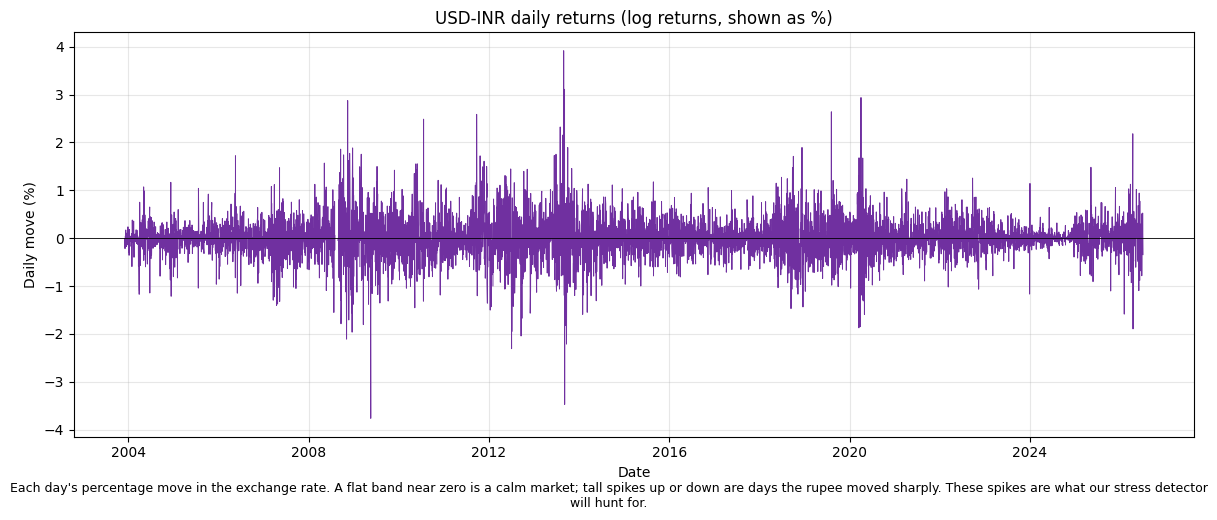

In [89]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(features.index, features["log_return"] * 100, color="#7030a0", linewidth=0.7)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("USD-INR daily returns (log returns, shown as %)")
ax.set_xlabel("Date")
ax.set_ylabel("Daily move (%)")
ax.grid(True, alpha=0.3)
plt.figtext(0.5, -0.02,
    "Each day's percentage move in the exchange rate. A flat band near zero is a calm market; "
    "tall spikes up or down are days the rupee moved sharply. These spikes are what our stress detector will hunt for.",
    ha="center", fontsize=9, wrap=True)
plt.tight_layout()
plt.show()

### Step 1.9 — Chart 3: rolling volatility over time



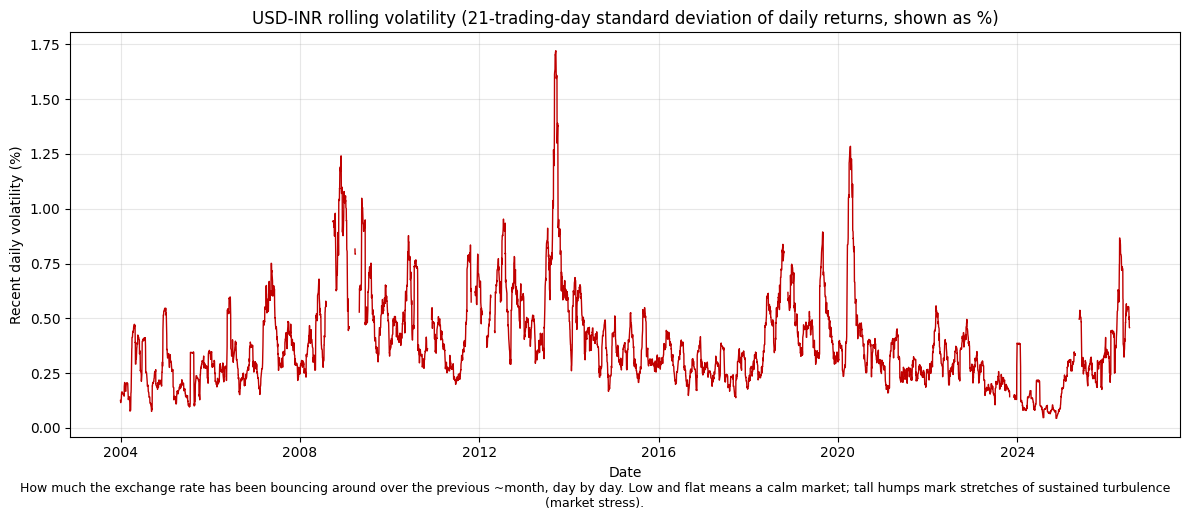

In [90]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(features.index, features["roll_vol_21"] * 100, color="#c00000", linewidth=1)
ax.set_title("USD-INR rolling volatility (21-trading-day standard deviation of daily returns, shown as %)")
ax.set_xlabel("Date")
ax.set_ylabel("Recent daily volatility (%)")
ax.grid(True, alpha=0.3)
plt.figtext(0.5, -0.02,
    "How much the exchange rate has been bouncing around over the previous ~month, day by day. "
    "Low and flat means a calm market; tall humps mark stretches of sustained turbulence (market stress).",
    ha="center", fontsize=9, wrap=True)
plt.tight_layout()
plt.show()

<!-- STAGE2_START -->
# Stage 2 — Building the Detector: an Isolation Forest for Abnormal Days



### Step 2.1 — Prepare the inputs, and handle missing values

**What this does.** It assembles the exact two-column table of numbers the model will look at — `abs_log_return` and `roll_vol_21` — and removes the rows where either value is missing.


In [91]:
# Today's move size, ignoring direction (magnitude), as agreed.
features["abs_log_return"] = features["log_return"].abs()

feature_cols = ["abs_log_return", "roll_vol_21"]
is_complete = features[feature_cols].notna().all(axis=1)   # rows the model can assess
X = features.loc[is_complete, feature_cols]

print("Total rows in feature table     :", len(features))
print("Rows the model will ASSESS      :", int(is_complete.sum()))
print("Rows EXCLUDED (a feature is NaN):", int((~is_complete).sum()))
print("   ...of which gap-spanned days :", int(features.loc[~is_complete, "gap_spanned"].sum()))
print("   ...of which bad-tick days    :", int(features.loc[~is_complete, "bad_tick"].sum()))
print("   ...of which early/no-vol days:",
      int(((~is_complete) & ~features["gap_spanned"] & ~features["bad_tick"]).sum()))
print("\nConfirmation: excluded rows are dropped, NOT filled. No invented values are used.")
print("Feature matrix X shape:", X.shape)

Total rows in feature table     : 5859
Rows the model will ASSESS      : 5608
Rows EXCLUDED (a feature is NaN): 251
   ...of which gap-spanned days : 2
   ...of which bad-tick days    : 10
   ...of which early/no-vol days: 239

Confirmation: excluded rows are dropped, NOT filled. No invented values are used.
Feature matrix X shape: (5608, 2)


### Step 2.2 — Fit the Isolation Forest and score every assessed day

We train the Isolation Forest on the clean feature matrix, gives every assessed day an anomaly score, and turns those scores into a flag.

 We use `n_estimators = 200` (build 200 random-cutting trees and average them — enough for a stable result), `contamination = 0.02` (flag ~2% of assessed days, as agreed), and `random_state = 42` (the fixed seed for repeatability).



We record the outcome with a three-way **`status`** label so the excluded days are never mistaken for cleared days:
- `not_assessed` — the row was excluded (missing feature); the detector never judged it.
- `normal` — assessed and **not** flagged.
- `anomaly` — assessed and flagged.

We also keep `anomaly_flag` as a *nullable* integer: `1`/`0` for assessed days, and a true blank (`<NA>`) for not-assessed days — so a `0` always means the detector looked at this day and cleared it, never that we did not look.

In [92]:
from sklearn.ensemble import IsolationForest

RANDOM_SEED   = 42
N_ESTIMATORS  = 200
CONTAMINATION = 0.02
print(f"Settings -> n_estimators={N_ESTIMATORS}, contamination={CONTAMINATION}, random_state={RANDOM_SEED}")

model = IsolationForest(n_estimators=N_ESTIMATORS, contamination=CONTAMINATION, random_state=RANDOM_SEED)
model.fit(X)

prediction = model.predict(X)            # -1 = anomaly, 1 = normal
anomaly_score = -model.score_samples(X)  # negate so higher = more anomalous

# Attach results, keeping "not assessed" distinct from "assessed & normal".
features["anomaly_score"] = np.nan
features.loc[X.index, "anomaly_score"] = anomaly_score

features["anomaly_flag"] = pd.array([pd.NA] * len(features), dtype="Int64")  # <NA> for not-assessed
features.loc[X.index, "anomaly_flag"] = (prediction == -1).astype(int)

features["status"] = "not_assessed"
features.loc[X.index[prediction == 1],  "status"] = "normal"
features.loc[X.index[prediction == -1], "status"] = "anomaly"

print("\nStatus breakdown (three distinct categories):")
print(features["status"].value_counts())

Settings -> n_estimators=200, contamination=0.02, random_state=42

Status breakdown (three distinct categories):
status
normal          5495
not_assessed     251
anomaly          113
Name: count, dtype: int64


### Step 2.3 — Summary: how many days were flagged

We check how many days were flagged, as a fraction of the days actually assessed, and the date span those flags cover.


In [93]:
n_assessed = int((features["status"] != "not_assessed").sum())
n_flagged  = int((features["status"] == "anomaly").sum())
flagged_rows = features[features["status"] == "anomaly"]

print("Assessed days            :", n_assessed)
print("Flagged as anomalies     :", n_flagged)
print("Flag rate (of assessed)  :", round(100 * n_flagged / n_assessed, 3), "%  (target ~2.0%)")
print("Flag rate (of all rows)  :", round(100 * n_flagged / len(features), 3), "%")
print("Flagged dates span       :", flagged_rows.index.min().date(), "->", flagged_rows.index.max().date())

Assessed days            : 5608
Flagged as anomalies     : 113
Flag rate (of assessed)  : 2.015 %  (target ~2.0%)
Flag rate (of all rows)  : 1.929 %
Flagged dates span       : 2006-05-18 -> 2026-04-15


### Step 2.4 — The flagged days

We lists every flagged day, sorted from most to least anomalous, showing the date, the closing rate, that day's log return, and the rolling volatility.


In [94]:
flagged_sorted = flagged_rows.sort_values("anomaly_score", ascending=False)
flagged_view = flagged_sorted[["close", "log_return", "roll_vol_21", "anomaly_score"]].round(5)

print(f"All {len(flagged_view)} flagged days, most anomalous first:\n")
print(flagged_view.to_string())

All 113 flagged days, most anomalous first:

              close  log_return  roll_vol_21  anomaly_score
Date                                                       
2013-09-05  66.2700    -0.03470      0.01613        0.82770
2013-09-20  62.1900    -0.02210      0.01594        0.81299
2013-08-28  66.8600     0.03915      0.01269        0.80942
2013-09-04  68.6100     0.03109      0.01356        0.80888
2013-09-10  64.0600    -0.01822      0.01702        0.79881
2020-04-02  77.5700     0.02937      0.01210        0.79477
2009-05-18  47.5880    -0.03761      0.01048        0.78303
2013-09-30  62.9100     0.01894      0.01390        0.78038
2008-11-12  49.2850     0.02873      0.01043        0.77010
2013-09-09  65.2380    -0.01173      0.01637        0.76236
2008-11-28  49.8700     0.01772      0.01235        0.76032
2013-08-22  64.6900     0.02077      0.01037        0.75616
2008-11-21  49.5480    -0.01707      0.01185        0.75539
2020-04-16  77.2125     0.01674      0.01203        0.7

In [95]:
# This column will hold the counts of occurances of volatility in a year
yearly_volatility_count_df = flagged_rows.groupby(flagged_rows.index.year).size().reset_index(name='volatile_days_count')

# Rename the columns for a clean presentation
yearly_volatility_count_df.columns = ['Year', 'Volatile Days Count']

# Print the table
print("Count of Volatile Days by Year:")
print(yearly_volatility_count_df.to_string(index=False))

'''
The algorithm flagged these days purely based on
the math of the exchange rate, but these mathematical spikes
line up perfectly with three of the most severe
global economic shocks of the 21st century:
2008 (GFC), 2013 (Taper Tantrum), and 2020 COVID-19.
'''

Count of Volatile Days by Year:
 Year  Volatile Days Count
 2006                    1
 2007                    1
 2008                   26
 2009                    3
 2010                    3
 2011                    3
 2012                    7
 2013                   34
 2014                    2
 2018                    5
 2019                    1
 2020                   24
 2026                    3


'\nThe algorithm flagged these days purely based on\nthe math of the exchange rate, but these mathematical spikes\nline up perfectly with three of the most severe\nglobal economic shocks of the 21st century:\n2008 (GFC), 2013 (Taper Tantrum), and 2020 COVID-19.\n'

### Step 2.5 —  where the flagged days fall



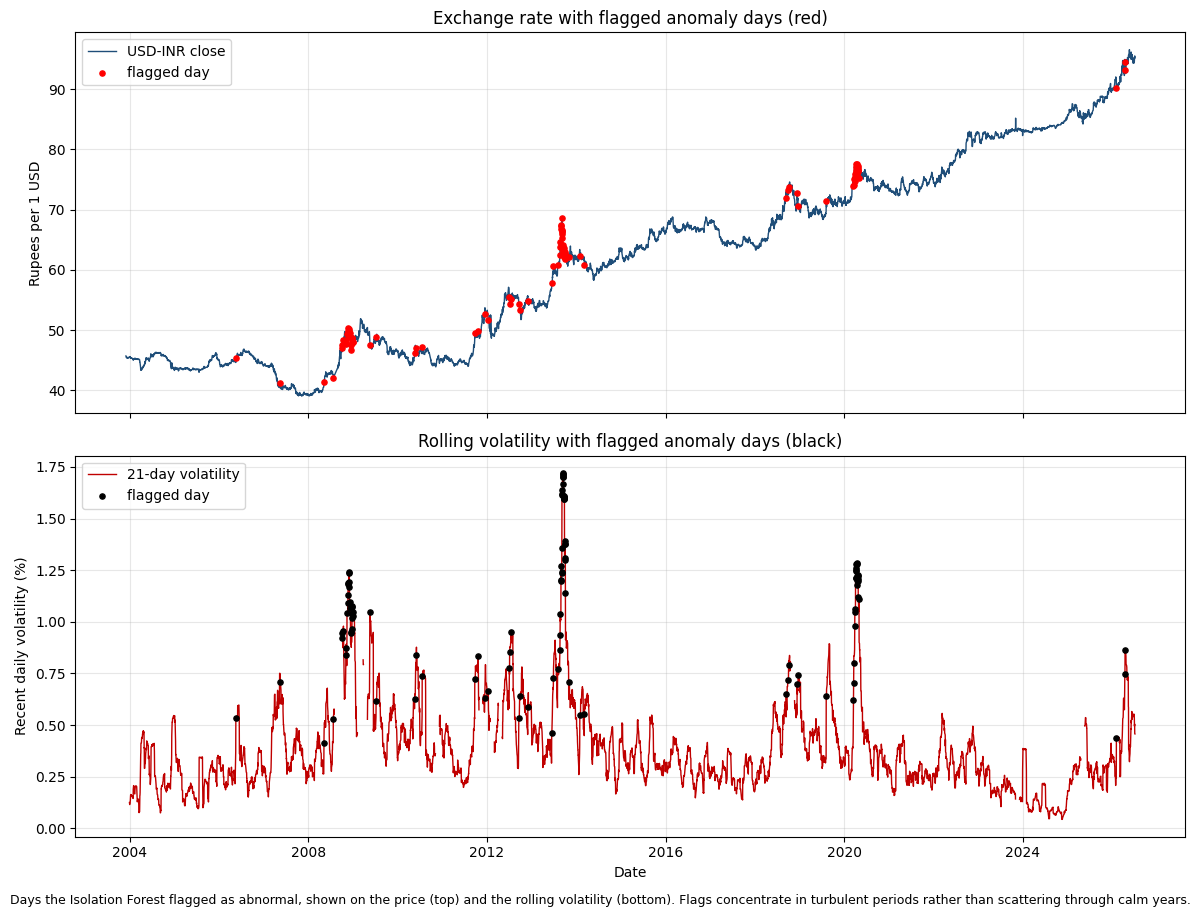

In [96]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

ax1.plot(features.index, features["close"], color="#1f4e79", linewidth=1, label="USD-INR close")
ax1.scatter(flagged_rows.index, flagged_rows["close"], color="red", s=14, zorder=3, label="flagged day")
ax1.set_ylabel("Rupees per 1 USD")
ax1.set_title("Exchange rate with flagged anomaly days (red)")
ax1.legend(loc="upper left"); ax1.grid(True, alpha=0.3)

ax2.plot(features.index, features["roll_vol_21"] * 100, color="#c00000", linewidth=1, label="21-day volatility")
ax2.scatter(flagged_rows.index, flagged_rows["roll_vol_21"] * 100, color="black", s=14, zorder=3, label="flagged day")
ax2.set_ylabel("Recent daily volatility (%)"); ax2.set_xlabel("Date")
ax2.set_title("Rolling volatility with flagged anomaly days (black)")
ax2.legend(loc="upper left"); ax2.grid(True, alpha=0.3)

plt.figtext(0.5, -0.01,
    "Days the Isolation Forest flagged as abnormal, shown on the price (top) and the rolling "
    "volatility (bottom). Flags concentrate in turbulent periods rather than scattering through calm years.",
    ha="center", fontsize=9, wrap=True)
plt.tight_layout()
plt.show()

In [97]:
print("1) Flag rate vs target:")
print("   flagged / assessed =", round(100 * n_flagged / n_assessed, 3), "%  (contamination target = 2.0%)")

print("\n2) Flagged days per calendar year (look for clustering in stress years):")
print(flagged_rows.groupby(flagged_rows.index.year).size().to_string())

print("\n3) Leakage check (must be zero -- these were excluded before detection):")
print("   flagged days that are bad-tick   :", int(flagged_rows["bad_tick"].sum()))
print("   flagged days that are gap-spanned:", int(flagged_rows["gap_spanned"].sum()))

1) Flag rate vs target:
   flagged / assessed = 2.015 %  (contamination target = 2.0%)

2) Flagged days per calendar year (look for clustering in stress years):
Date
2006     1
2007     1
2008    26
2009     3
2010     3
2011     3
2012     7
2013    34
2014     2
2018     5
2019     1
2020    24
2026     3

3) Leakage check (must be zero -- these were excluded before detection):
   flagged days that are bad-tick   : 0
   flagged days that are gap-spanned: 0


<!-- STAGE3_START -->
# Stage 3 — Backtesting: Do the Flagged Days Match Real Stress Episodes?



### Step 3.1 — Group the flagged days into time-based clusters



In [98]:
flagged = features[features["status"] == "anomaly"].sort_index().copy()

CLUSTER_GAP_DAYS = 21
gap_to_prev = flagged.index.to_series().diff().dt.days
flagged["cluster"] = (gap_to_prev > CLUSTER_GAP_DAYS).cumsum().astype(int).values

cluster_rows = []
for cid, g in flagged.groupby("cluster"):
    cluster_rows.append({
        "cluster": cid,
        "start": g.index.min().date(),
        "end": g.index.max().date(),
        "n_flagged_days": len(g),
        "span_days": (g.index.max() - g.index.min()).days,
        "peak_vol_pct": round(float(g["roll_vol_21"].max()) * 100, 3),
        "peak_anom_score": round(float(g["anomaly_score"].max()), 4),
    })
clusters = pd.DataFrame(cluster_rows)

print("Flagged days:", len(flagged), " ->  grouped into", len(clusters), "clusters (21-day threshold)\n")
print(clusters.to_string(index=False))

Flagged days: 113  ->  grouped into 28 clusters (21-day threshold)

 cluster      start        end  n_flagged_days  span_days  peak_vol_pct  peak_anom_score
       0 2006-05-18 2006-05-18               1          0         0.536           0.7009
       1 2007-05-10 2007-05-10               1          0         0.707           0.6726
       2 2008-05-07 2008-05-07               1          0         0.415           0.6876
       3 2008-07-23 2008-07-23               1          0         0.529           0.6849
       4 2008-10-03 2008-10-10               3          7         0.955           0.7173
       5 2008-11-03 2009-01-01              22         59         1.241           0.7701
       6 2009-05-18 2009-05-18               1          0         1.048           0.7830
       7 2009-07-08 2009-07-08               1          0         0.618           0.6653
       8 2010-05-19 2010-06-01               2         13         0.842           0.7002
       9 2010-07-20 2010-07-20            

### Step 3.2 — Assign a candidate episode and confidence tier to each cluster


We define a small set of **broad historical windows** and tag each cluster by which window (if any) its dates fall in.:
- **HIGH windows** — three globally-established crisis periods. A cluster overlapping one of these is HIGH. These broad periods are matters of public record.
- **MEDIUM windows** — two periods we *propose* as plausible stress eras. A cluster overlapping one of these, but not a HIGH window, is MEDIUM
- **Everything else is LOW / UNEXPLAINED**



In [99]:
import pandas as pd

# --- Broad, well-established crisis windows (safe to name the PERIOD). HIGH tier. ---
HIGH_WINDOWS = {
    "Global financial crisis (2008-09)":      ("2008-09-01", "2009-03-31"),
    "US 'taper tantrum' EM sell-off (2013)":  ("2013-05-01", "2013-10-31"),
    "COVID-19 market shock (2020)":           ("2020-02-15", "2020-05-31"),
}
# --- Analyst-proposed plausible stress eras -- NOT established fact. MEDIUM tier. ---
MEDIUM_WINDOWS = {
    "Eurozone-crisis / rupee-depreciation era (2011-2012)": ("2011-07-01", "2012-12-31"),
    "Emerging-market sell-off / rupee pressure (2018)":     ("2018-08-01", "2018-12-31"),
}

def overlaps(cstart, cend, wstart, wend):
    return not (pd.Timestamp(cend) < pd.Timestamp(wstart) or pd.Timestamp(cstart) > pd.Timestamp(wend))

def classify(cstart, cend):
    for name, (ws, we) in HIGH_WINDOWS.items():
        if overlaps(cstart, cend, ws, we):
            return name, "HIGH"
    for name, (ws, we) in MEDIUM_WINDOWS.items():
        if overlaps(cstart, cend, ws, we):
            return name, "MEDIUM"
    return "(no known episode)", "LOW-UNEXPLAINED"

clusters[["candidate_episode", "confidence_tier"]] = clusters.apply(
    lambda r: pd.Series(classify(r["start"], r["end"])), axis=1)

summary = clusters[["start", "end", "n_flagged_days", "peak_vol_pct",
                    "candidate_episode", "confidence_tier"]]
print("CLUSTER SUMMARY TABLE (one row per cluster):\n")
print(summary.to_string(index=False))

CLUSTER SUMMARY TABLE (one row per cluster):

     start        end  n_flagged_days  peak_vol_pct                                    candidate_episode confidence_tier
2006-05-18 2006-05-18               1         0.536                                   (no known episode) LOW-UNEXPLAINED
2007-05-10 2007-05-10               1         0.707                                   (no known episode) LOW-UNEXPLAINED
2008-05-07 2008-05-07               1         0.415                                   (no known episode) LOW-UNEXPLAINED
2008-07-23 2008-07-23               1         0.529                                   (no known episode) LOW-UNEXPLAINED
2008-10-03 2008-10-10               3         0.955                    Global financial crisis (2008-09)            HIGH
2008-11-03 2009-01-01              22         1.241                    Global financial crisis (2008-09)            HIGH
2009-05-18 2009-05-18               1         1.048                                   (no known episode) LO

### Step 3.3 — The unexplained list

We put the clustors outside 2008, 2011-12, 2013, 2018, and 2020 in the LOW-UNEXPLAINED tier.


In [100]:
unexplained = clusters[clusters["confidence_tier"] == "LOW-UNEXPLAINED"]
print("Clusters with NO confident explanation (require investigation):",
      len(unexplained), "clusters,", int(unexplained["n_flagged_days"].sum()), "flagged days\n")
print(unexplained[["start", "end", "n_flagged_days", "peak_vol_pct"]].to_string(index=False))
print("\nThese are reported as UNEXPLAINED. No event story is attached to them.")

Clusters with NO confident explanation (require investigation): 14 clusters, 16 flagged days

     start        end  n_flagged_days  peak_vol_pct
2006-05-18 2006-05-18               1         0.536
2007-05-10 2007-05-10               1         0.707
2008-05-07 2008-05-07               1         0.415
2008-07-23 2008-07-23               1         0.529
2009-05-18 2009-05-18               1         1.048
2009-07-08 2009-07-08               1         0.618
2010-05-19 2010-06-01               2         0.842
2010-07-20 2010-07-20               1         0.739
2013-11-01 2013-11-01               1         0.711
2014-01-29 2014-01-29               1         0.551
2014-03-07 2014-03-07               1         0.555
2019-08-06 2019-08-06               1         0.640
2026-02-03 2026-02-03               1         0.439
2026-04-13 2026-04-15               2         0.866

These are reported as UNEXPLAINED. No event story is attached to them.


### Step 3.5 — How much of the detector's output lands in known crises?

We reports the splits of the 113 flagged days across the three tiers



In [101]:
by_tier_days = clusters.groupby("confidence_tier")["n_flagged_days"].sum()
by_tier_clusters = clusters.groupby("confidence_tier").size()
total = int(clusters["n_flagged_days"].sum())

print("Flagged days by confidence tier (of", total, "total):\n")
for tier in ["HIGH", "MEDIUM", "LOW-UNEXPLAINED"]:
    d = int(by_tier_days.get(tier, 0)); c = int(by_tier_clusters.get(tier, 0))
    print(f"  {tier:<16}: {d:>3} days ({100*d/total:5.1f}%)  across {c} cluster(s)")

high = int(by_tier_days.get("HIGH", 0))
print(f"\nHeadline: {high} of {total} flagged days ({100*high/total:.1f}%) fall in the three "
      f"broadly-established crisis periods (2008-09 GFC, 2013 taper tantrum, 2020 COVID).")
print("MEDIUM and LOW figures are reported as-is; MEDIUM are leads to verify, LOW are left unexplained.")

Flagged days by confidence tier (of 113 total):

  HIGH            :  82 days ( 72.6%)  across 5 cluster(s)
  MEDIUM          :  15 days ( 13.3%)  across 9 cluster(s)
  LOW-UNEXPLAINED :  16 days ( 14.2%)  across 14 cluster(s)

Headline: 82 of 113 flagged days (72.6%) fall in the three broadly-established crisis periods (2008-09 GFC, 2013 taper tantrum, 2020 COVID).
MEDIUM and LOW figures are reported as-is; MEDIUM are leads to verify, LOW are left unexplained.


<!-- STAGE4_START -->
# Stage 4 — The Market Stress Index



### Step 4.1 — Build the index and describe how it behaves

We create a Market Stress Index column (rolling volatility in daily-percent units) and prints how it behaves: its calm baseline, a low "very calm" level, and its crisis peak with the date.

 We multiply the rolling volatility by 100, then compute the median (our calm baseline), the 10th percentile (a "typically very calm" level), and the maximum with its date. We also list the peak index value inside each HIGH-confidence crisis cluster from Stage 3.

In [102]:
features["stress_index"] = features["roll_vol_21"] * 100   # daily % volatility; index IS the turbulence

idx = features["stress_index"].dropna()
calm_baseline = idx.median()
very_calm     = idx.quantile(0.10)
peak_value    = idx.max()
peak_date     = idx.idxmax()

print("MARKET STRESS INDEX  (= 21-day rolling volatility x 100, in daily %)")
print("  Calm baseline (median)      :", round(calm_baseline, 4), "%")
print("  Very-calm level (10th pct)  :", round(very_calm, 4), "%")
print("  Crisis peak                 :", round(peak_value, 4), "% on", peak_date.date())
print("  Peak is", round(peak_value / calm_baseline, 2), "x the calm baseline")
print("\nPeak index within each HIGH-confidence crisis cluster (from Stage 3):")
print(clusters.loc[clusters["confidence_tier"] == "HIGH",
                   ["start", "end", "n_flagged_days", "peak_vol_pct"]].to_string(index=False))

MARKET STRESS INDEX  (= 21-day rolling volatility x 100, in daily %)
  Calm baseline (median)      : 0.3385 %
  Very-calm level (10th pct)  : 0.185 %
  Crisis peak                 : 1.7211 % on 2013-09-16
  Peak is 5.08 x the calm baseline

Peak index within each HIGH-confidence crisis cluster (from Stage 3):
     start        end  n_flagged_days  peak_vol_pct
2008-10-03 2008-10-10               3         0.955
2008-11-03 2009-01-01              22         1.241
2013-06-13 2013-06-27               2         0.729
2013-07-31 2013-10-03              31         1.721
2020-03-16 2020-04-30              24         1.285


### Step 4.2 — Market Stress Index over the full history

We plot the event in one figure. We fill the area under the index, add a dashed baseline at the median, overlay the flagged anomaly days as red points, and shade each broad HIGH-confidence crisis window (reusing the `HIGH_WINDOWS` periods from Stage 3) with a text label.

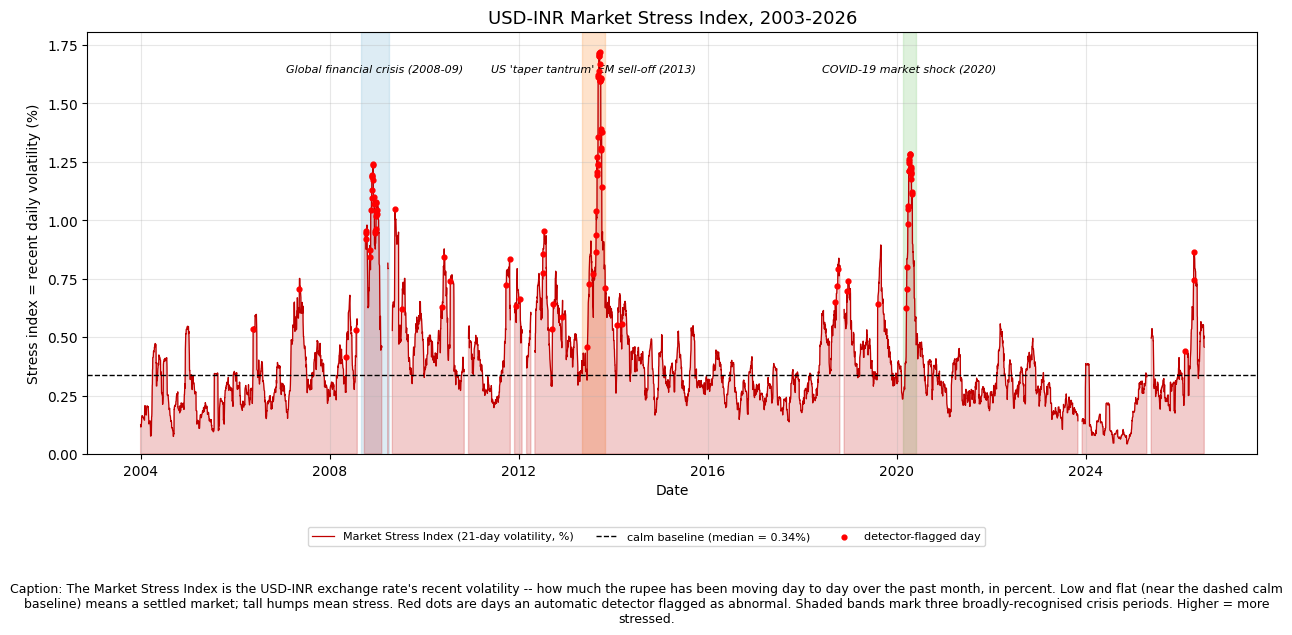

In [103]:
flagged_days = features[features["status"] == "anomaly"]

MAIN_CAPTION = (
    "Caption: The Market Stress Index is the USD-INR exchange rate's recent volatility -- how much the rupee "
    "has been moving day to day over the past month, in percent. Low and flat (near the dashed calm baseline) "
    "means a settled market; tall humps mean stress. Red dots are days an automatic detector flagged as abnormal. "
    "Shaded bands mark three broadly-recognised crisis periods. Higher = more stressed."
)

def make_main_stress_figure():
    # Build the full-history centerpiece. Legend sits BELOW the plot so it never overlaps the
    # crisis-band labels (this placement is the only change from the first draft; it is purely cosmetic).
    fig, ax = plt.subplots(figsize=(13, 6.5))
    band_colors = ["#9ecae1", "#fdae6b", "#a1d99b"]
    for (label, (ws, we)), col in zip(HIGH_WINDOWS.items(), band_colors):
        ax.axvspan(pd.Timestamp(ws), pd.Timestamp(we), color=col, alpha=0.35, zorder=0)
        mid = pd.Timestamp(ws) + (pd.Timestamp(we) - pd.Timestamp(ws)) / 2
        ax.text(mid, peak_value * 0.97, label, ha="center", va="top", fontsize=8, style="italic")
    ax.fill_between(features.index, 0, features["stress_index"], color="#c00000", alpha=0.20, zorder=1)
    ax.plot(features.index, features["stress_index"], color="#c00000", linewidth=0.9, zorder=2,
            label="Market Stress Index (21-day volatility, %)")
    ax.axhline(calm_baseline, color="black", linestyle="--", linewidth=1, zorder=3,
               label=f"calm baseline (median = {calm_baseline:.2f}%)")
    ax.scatter(flagged_days.index, flagged_days["stress_index"], color="red", s=12, zorder=4,
               label="detector-flagged day")
    ax.set_title("USD-INR Market Stress Index, 2003-2026", fontsize=13)
    ax.set_xlabel("Date"); ax.set_ylabel("Stress index = recent daily volatility (%)")
    ax.set_ylim(0, peak_value * 1.05)
    ax.grid(True, alpha=0.3)
    # Legend below the axes (cosmetic fix), caption below that. Manual bottom margin keeps both visible.
    h, l = ax.get_legend_handles_labels()
    fig.subplots_adjust(left=0.07, right=0.97, top=0.93, bottom=0.28)
    fig.legend(h, l, loc="lower center", bbox_to_anchor=(0.5, 0.13), ncol=3, fontsize=8, frameon=True)
    fig.text(0.5, 0.05, MAIN_CAPTION, ha="center", va="center", fontsize=9, wrap=True)
    return fig, ax

fig, ax = make_main_stress_figure()
plt.show()

## Step 4.3 — Zoomed view 1: the 2008 Global Financial Crisis


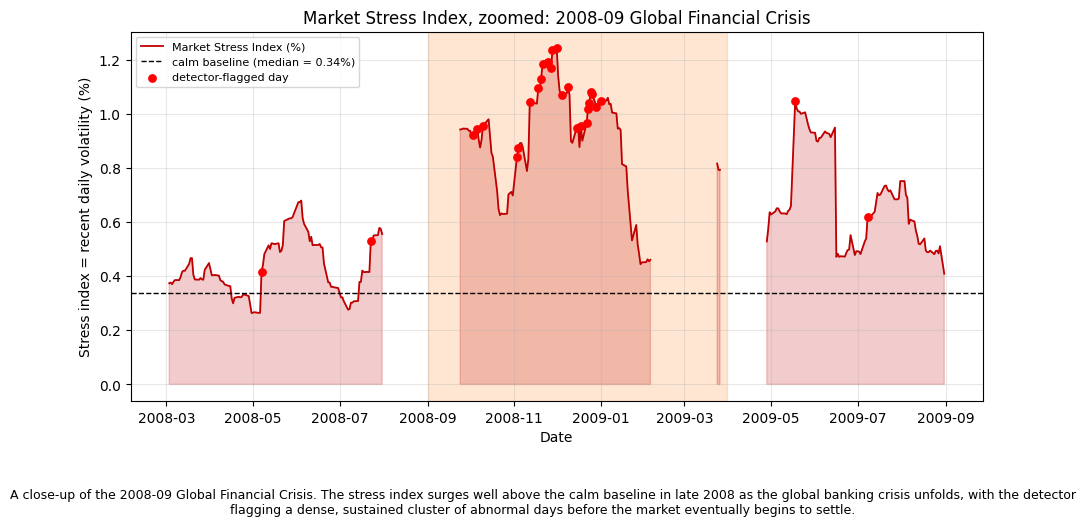

In [104]:
# Create a dedicated function for 2008 to fix the hardcoded background color
def plot_zoom_2008(start, end, period_label, period_window, caption):
    sub = features.loc[start:end]
    sub_flags = sub[sub["status"] == "anomaly"]
    fig, ax = plt.subplots(figsize=(11, 5.6))
    ws, we = pd.Timestamp(period_window[0]), pd.Timestamp(period_window[1])
    ax.axvspan(max(ws, sub.index.min()), min(we, sub.index.max()), color="#fdae6b", alpha=0.30, zorder=0)

    ax.fill_between(sub.index, 0, sub["stress_index"], color="#c00000", alpha=0.20, zorder=1)
    ax.plot(sub.index, sub["stress_index"], color="#c00000", linewidth=1.3, zorder=2,
            label="Market Stress Index (%)")
    ax.axhline(calm_baseline, color="black", linestyle="--", linewidth=1, zorder=3,
               label=f"calm baseline (median = {calm_baseline:.2f}%)")
    ax.scatter(sub_flags.index, sub_flags["stress_index"], color="red", s=28, zorder=4,
               label="detector-flagged day")
    ax.set_title(f"Market Stress Index, zoomed: {period_label}", fontsize=12)
    ax.set_xlabel("Date"); ax.set_ylabel("Stress index = recent daily volatility (%)")
    ax.legend(loc="upper left", fontsize=8); ax.grid(True, alpha=0.3)
    fig.subplots_adjust(bottom=0.22)
    fig.text(0.5, 0.04, caption, ha="center", va="center", fontsize=9, wrap=True)
    return fig, ax

ZOOM2008_CAPTION = (
    "A close-up of the 2008-09 Global Financial Crisis. The stress index "
    "surges well above the calm baseline in late 2008 as the global banking crisis unfolds, "
    "with the detector flagging a dense, sustained cluster of abnormal days before the market "
    "eventually begins to settle."
)

fig, ax = plot_zoom_2008("2008-03-01", "2009-08-31", "2008-09 Global Financial Crisis",
                    HIGH_WINDOWS["Global financial crisis (2008-09)"], ZOOM2008_CAPTION)
plt.show()

### Step 4.4 — Zoomed view 2: the 2013 taper tantrum


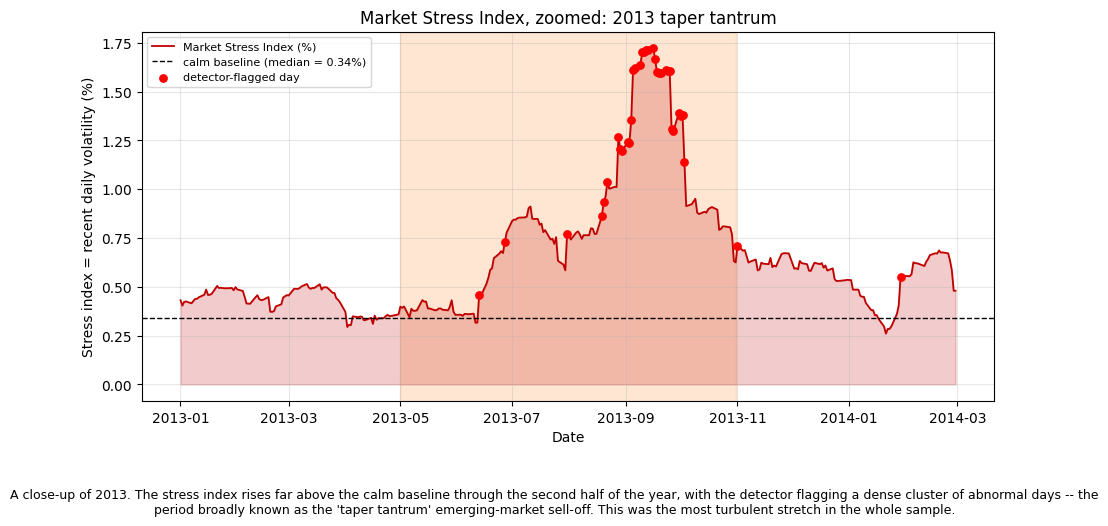

In [105]:
def plot_zoom(start, end, period_label, period_window, caption):
    sub = features.loc[start:end]
    sub_flags = sub[sub["status"] == "anomaly"]
    fig, ax = plt.subplots(figsize=(11, 5.6))
    ws, we = pd.Timestamp(period_window[0]), pd.Timestamp(period_window[1])
    ax.axvspan(max(ws, sub.index.min()), min(we, sub.index.max()), color="#fdae6b", alpha=0.30, zorder=0)
    ax.fill_between(sub.index, 0, sub["stress_index"], color="#c00000", alpha=0.20, zorder=1)
    ax.plot(sub.index, sub["stress_index"], color="#c00000", linewidth=1.3, zorder=2,
            label="Market Stress Index (%)")
    ax.axhline(calm_baseline, color="black", linestyle="--", linewidth=1, zorder=3,
               label=f"calm baseline (median = {calm_baseline:.2f}%)")
    ax.scatter(sub_flags.index, sub_flags["stress_index"], color="red", s=28, zorder=4,
               label="detector-flagged day")
    ax.set_title(f"Market Stress Index, zoomed: {period_label}", fontsize=12)
    ax.set_xlabel("Date"); ax.set_ylabel("Stress index = recent daily volatility (%)")
    ax.legend(loc="upper left", fontsize=8); ax.grid(True, alpha=0.3)
    fig.subplots_adjust(bottom=0.22)
    fig.text(0.5, 0.04, caption, ha="center", va="center", fontsize=9, wrap=True)
    return fig, ax

ZOOM2013_CAPTION = (
    "A close-up of 2013. The stress index rises far above the calm baseline through the second half of "
    "the year, with the detector flagging a dense cluster of abnormal days -- the period broadly known as the "
    "'taper tantrum' emerging-market sell-off. This was the most turbulent stretch in the whole sample.")
fig, ax = plot_zoom("2013-01-01", "2014-02-28", "2013 taper tantrum",
                    HIGH_WINDOWS["US 'taper tantrum' EM sell-off (2013)"], ZOOM2013_CAPTION)
plt.show()

### Step 4.5 — Zoomed view 3: the 2020 COVID-19 shock


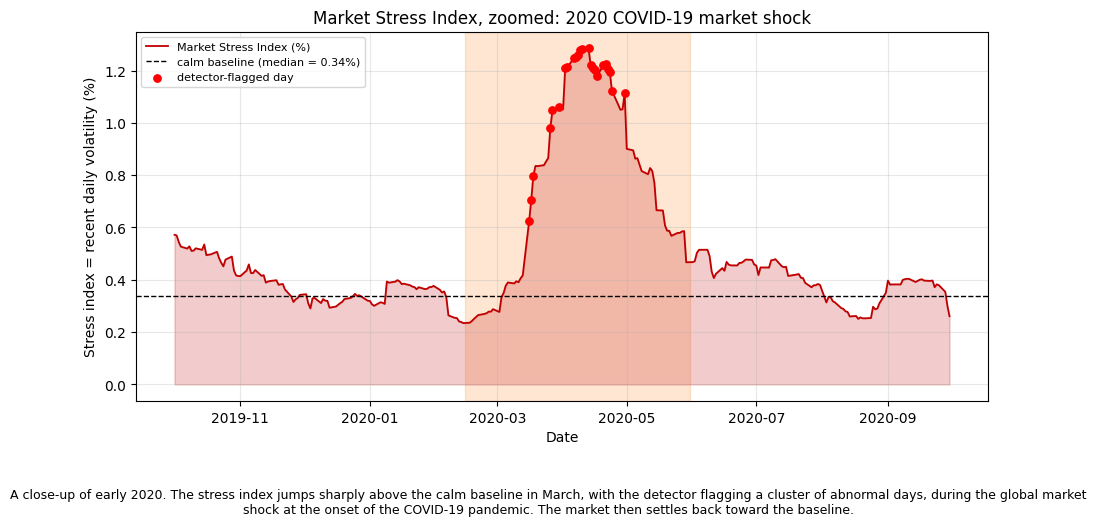

In [106]:
ZOOM2020_CAPTION = (
    "A close-up of early 2020. The stress index jumps sharply above the calm baseline in March, with "
    "the detector flagging a cluster of abnormal days, during the global market shock at the onset of the "
    "COVID-19 pandemic. The market then settles back toward the baseline.")
fig, ax = plot_zoom("2019-10-01", "2020-09-30", "2020 COVID-19 market shock",
                    HIGH_WINDOWS["COVID-19 market shock (2020)"], ZOOM2020_CAPTION)
plt.show()

### Step 4.5 — Verify the index

We checks that the index behaves as our earlier stages established and that our construction introduced no distortion.


In [107]:
# 1) Highest point of the index
print("Index peak date :", peak_date.date(), "  value:", round(peak_value, 4), "%")
print("  -> matches the 2013 taper tantrum identified in Stages 1 & 3:",
      peak_date.year == 2013)

# 2) Calm vs crisis separation
print("\nCalm baseline   :", round(calm_baseline, 4), "%   Crisis peak:", round(peak_value, 4),
      "%   ratio:", round(peak_value / calm_baseline, 2), "x")

# 3) Shape preserved by the x100 rescale (should be exactly 1.000)
paired = features[["roll_vol_21", "stress_index"]].dropna()
corr = paired["roll_vol_21"].corr(paired["stress_index"])
print("\nCorrelation of index with raw rolling volatility:", round(corr, 6),
      "  (1.000000 => identical shape, only the axis units changed)")

Index peak date : 2013-09-16   value: 1.7211 %
  -> matches the 2013 taper tantrum identified in Stages 1 & 3: True

Calm baseline   : 0.3385 %   Crisis peak: 1.7211 %   ratio: 5.08 x

Correlation of index with raw rolling volatility: 1.0   (1.000000 => identical shape, only the axis units changed)


<!-- STAGE5_START -->
# Stage 5 — Saving the Outputs



### Step 5.1 — Set up the output folder and filenames


In [108]:
import os
OUT = "../outputs"
os.makedirs(OUT, exist_ok=True)   # created in Stage 0; harmless if it already exists

paths = {
    "fig_main":     f"{OUT}/market_stress_index_full_history.png",
    "fig_2013":     f"{OUT}/market_stress_index_zoom_2013_taper_tantrum.png",
    "fig_2020":     f"{OUT}/market_stress_index_zoom_2020_covid.png",
    "csv_features": f"{OUT}/feature_table_full.csv",
    "csv_flagged":  f"{OUT}/flagged_anomaly_days.csv",
    "csv_clusters": f"{OUT}/cluster_summary.csv",
    "summary":      f"{OUT}/results_summary.md",
}
for k, v in paths.items():
    print(f"{k:13s} -> {v}")

fig_main      -> ../outputs/market_stress_index_full_history.png
fig_2013      -> ../outputs/market_stress_index_zoom_2013_taper_tantrum.png
fig_2020      -> ../outputs/market_stress_index_zoom_2020_covid.png
csv_features  -> ../outputs/feature_table_full.csv
csv_flagged   -> ../outputs/flagged_anomaly_days.csv
csv_clusters  -> ../outputs/cluster_summary.csv
summary       -> ../outputs/results_summary.md


### Step 5.2 — Save the figures at 300 DPI



In [109]:
print("Cosmetic check: the ONLY change to the centerpiece figure is the legend position")
print("(moved from top-right to below the plot). No data, axis, or value was modified.\n")

fig, _ = make_main_stress_figure()
fig.savefig(paths["fig_main"], dpi=300, bbox_inches="tight"); plt.close(fig)

fig, _ = plot_zoom("2013-01-01", "2014-02-28", "2013 taper tantrum",
                   HIGH_WINDOWS["US 'taper tantrum' EM sell-off (2013)"], ZOOM2013_CAPTION)
fig.savefig(paths["fig_2013"], dpi=300, bbox_inches="tight"); plt.close(fig)

fig, _ = plot_zoom("2019-10-01", "2020-09-30", "2020 COVID-19 market shock",
                   HIGH_WINDOWS["COVID-19 market shock (2020)"], ZOOM2020_CAPTION)
fig.savefig(paths["fig_2020"], dpi=300, bbox_inches="tight"); plt.close(fig)

for key in ["fig_main", "fig_2013", "fig_2020"]:
    kb = os.path.getsize(paths[key]) / 1024
    print(f"saved {os.path.basename(paths[key]):48s} {kb:8.1f} KB")

Cosmetic check: the ONLY change to the centerpiece figure is the legend position
(moved from top-right to below the plot). No data, axis, or value was modified.

saved market_stress_index_full_history.png                528.0 KB
saved market_stress_index_zoom_2013_taper_tantrum.png     283.2 KB
saved market_stress_index_zoom_2020_covid.png             272.9 KB


### Step 5.3 — Save the result tables as CSV



In [110]:
# 1) Full feature table (complete audit trail).
features.to_csv(paths["csv_features"])

# 2) Flagged days, with cluster + tier attached, most anomalous first.
tier_lookup = clusters.set_index("cluster")[["candidate_episode", "confidence_tier"]]
flagged_out = flagged.join(tier_lookup, on="cluster").sort_values("anomaly_score", ascending=False)
flagged_cols = ["close", "log_return", "roll_vol_21", "anomaly_score",
                "cluster", "candidate_episode", "confidence_tier"]
flagged_out[flagged_cols].to_csv(paths["csv_flagged"])

# 3) Stage 3 cluster summary.
clusters.to_csv(paths["csv_clusters"], index=False)

print("Wrote 3 CSVs:")
print("  feature_table_full.csv     rows:", len(features), " cols:", features.shape[1])
print("  flagged_anomaly_days.csv   rows:", len(flagged_out))
print("  cluster_summary.csv        rows:", len(clusters))

Wrote 3 CSVs:
  feature_table_full.csv     rows: 5859  cols: 10
  flagged_anomaly_days.csv   rows: 113
  cluster_summary.csv        rows: 28
